# COPD Optimized Model Development

**Dataset:** NHANES 2011–2012  
**Objective:** Optimize and validate models for identifying *baseline pre-bronchodilator airflow obstruction*.

> **Important:** The target is an exploratory spirometric obstruction label (FEV1/FVC < 0.70), not a confirmed clinical COPD diagnosis. This notebook preserves the original cohort and target definition while improving model selection, validation, threshold selection, calibration, and model export.

## Workflow
1. Load NHANES XPT files and recreate the eligible cohort.
2. Construct the target and selected predictors.
3. Create a stratified hold-out test set.
4. Establish comparable baseline pipelines.
5. Tune Logistic Regression, Random Forest, and XGBoost using cross-validation on training data only.
6. Compare feature-ablation experiments.
7. Select an operating threshold using training-only out-of-fold predictions.
8. Evaluate once on the untouched test set.
9. Assess calibration and save complete pipelines.


## Stage 1: Setup

In [ ]:
# ------------------ Stage 1: Setup ------------------

%pip install -q pandas numpy matplotlib seaborn scikit-learn scipy xgboost shap

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, brier_score_loss
)

RANDOM_STATE = 42
N_SPLITS = 5

print("Setup complete.")

Setup complete.


## Stage 2: Load NHANES datasets

In [ ]:
# ------------------ Stage 2: Load NHANES XPT Files ------------------

uploaded = files.upload()
datasets = {}

for filename in uploaded:
    if filename.lower().endswith(".xpt"):
        datasets[filename.rsplit(".", 1)[0]] = pd.read_sas(
            filename, format="xport"
        )

required = ["DEMO_G", "SPX_G", "SMQ_G", "MCQ_G", "RDQ_G", "OCQ_G"]
missing_files = [name for name in required if name not in datasets]

if missing_files:
    raise ValueError(
        f"Missing required files: {missing_files}. "
        "Upload DEMO_G, SPX_G, SMQ_G, MCQ_G, RDQ_G and OCQ_G."
    )

for name in required:
    print(f"{name}: {datasets[name].shape}")

Saving DEMO_G.XPT to DEMO_G.XPT
Saving MCQ_G.XPT to MCQ_G.XPT
Saving OCQ_G.XPT to OCQ_G.XPT
Saving RDQ_G.XPT to RDQ_G.XPT
Saving SMQ_G.XPT to SMQ_G.XPT
Saving SPX_G.XPT to SPX_G.XPT
DEMO_G: (9756, 48)
SPX_G: (7495, 51)
SMQ_G: (6790, 30)
MCQ_G: (9364, 92)
RDQ_G: (9364, 15)
OCQ_G: (6175, 22)


## Stage 3: Recreate the baseline cohort and target

In [ ]:
# ------------------ Stage 3: Cohort and Target Construction ------------------

demo = datasets["DEMO_G"][["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1"]].copy()
spx = datasets["SPX_G"].copy()

cohort = demo.merge(spx, on="SEQN", how="inner")
cohort = cohort[cohort["RIDAGEYR"] >= 40].copy()

cohort["FEV1_FVC"] = cohort["SPXNFEV1"] / cohort["SPXNFVC"]

valid = cohort[
    (cohort["SPXNSTAT"] == 1) &
    (cohort["SPXNQFV1"].isin([b"A", b"B"])) &
    (cohort["SPXNQFVC"].isin([b"A", b"B"])) &
    (cohort["SPXNFVC"] > 0) &
    cohort["FEV1_FVC"].notna() &
    np.isfinite(cohort["FEV1_FVC"])
].copy()

valid["baseline_obstruction_flag"] = (
    valid["FEV1_FVC"] < 0.70
).astype(int)

print("Initial DEMO-SPX merge:", len(cohort))
print("Valid age 40+ spirometry cohort:", len(valid))
print("\nTarget distribution:")
print(valid["baseline_obstruction_flag"].value_counts())
print("\nTarget proportions:")
print(valid["baseline_obstruction_flag"].value_counts(normalize=True).round(4))

assert valid["SEQN"].is_unique, "Duplicate participant IDs found."
assert set(valid["baseline_obstruction_flag"].unique()).issubset({0, 1})

Initial DEMO-SPX merge: 3115
Valid age 40+ spirometry cohort: 2213

Target distribution:
baseline_obstruction_flag
0    1828
1     385
Name: count, dtype: int64

Target proportions:
baseline_obstruction_flag
0    0.826
1    0.174
Name: proportion, dtype: float64


## Stage 4: Merge questionnaire datasets

In [ ]:
# ------------------ Stage 4: Merge Questionnaire Data ------------------

copd_data = valid.copy()

for name in ["SMQ_G", "MCQ_G", "RDQ_G", "OCQ_G"]:
    # Avoid adding duplicate SEQN columns; merge on participant ID.
    copd_data = copd_data.merge(datasets[name], on="SEQN", how="left")

print("Merged dataset shape:", copd_data.shape)
print("Duplicate SEQN:", copd_data["SEQN"].duplicated().sum())
print("Target counts:")
print(copd_data["baseline_obstruction_flag"].value_counts())

assert copd_data["SEQN"].is_unique

Merged dataset shape: (2213, 211)
Duplicate SEQN: 0
Target counts:
baseline_obstruction_flag
0    1828
1     385
Name: count, dtype: int64


## Stage 5: Feature engineering and cleaning

In [ ]:
# ------------------ Stage 5: Feature Selection and Cleaning ------------------

selected_features = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH1",
    "SMQ020", "SMQ040", "SMD030",
    "MCQ160G", "MCQ160K",
    "RDQ031", "RDQ050", "RDQ070",
    "OCQ510", "OCQ530", "OCQ550", "OCQ570"
]

X_raw = copd_data[selected_features].copy()
y = copd_data["baseline_obstruction_flag"].astype(int).copy()

# Derive smoking status:
# 0 = never smoker; 1 = former smoker; 2 = current smoker.
X_raw["smoking_status"] = np.select(
    [
        X_raw["SMQ020"] == 2,
        (X_raw["SMQ020"] == 1) & (X_raw["SMQ040"] == 3),
        (X_raw["SMQ020"] == 1) & (X_raw["SMQ040"].isin([1, 2]))
    ],
    [0, 1, 2],
    default=np.nan
)

X_raw["age_started_smoking"] = X_raw["SMD030"].copy()

# NHANES special/non-response values are treated as missing.
X_raw["age_started_smoking"] = X_raw["age_started_smoking"].replace(
    [777, 999], np.nan
)
X_raw.loc[
    X_raw["age_started_smoking"] < 1,
    "age_started_smoking"
] = np.nan

# Remove source smoking columns after deriving the two model features.
X_raw.drop(columns=["SMQ020", "SMQ040", "SMD030"], inplace=True)

binary_cols = [
    "MCQ160G", "MCQ160K", "RDQ031", "RDQ050", "RDQ070",
    "OCQ510", "OCQ530", "OCQ550", "OCQ570"
]

for col in binary_cols:
    X_raw[col] = X_raw[col].replace({
        1: 1, 2: 0, 7: np.nan, 9: np.nan
    })

# Replace tiny floating-point representation of zero/special response in age.
X_raw["age_started_smoking"] = X_raw["age_started_smoking"].replace(
    [5.397605e-79], np.nan
)

print("Feature matrix:", X_raw.shape)
print("Features:", X_raw.columns.tolist())
print("\nMissing values:")
print(X_raw.isna().sum())
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix: (2213, 14)
Features: ['RIDAGEYR', 'RIAGENDR', 'RIDRETH1', 'MCQ160G', 'MCQ160K', 'RDQ031', 'RDQ050', 'RDQ070', 'OCQ510', 'OCQ530', 'OCQ550', 'OCQ570', 'smoking_status', 'age_started_smoking']

Missing values:
RIDAGEYR                  0
RIAGENDR                  0
RIDRETH1                  0
MCQ160G                   2
MCQ160K                   2
RDQ031                    0
RDQ050                    0
RDQ070                    0
OCQ510                   64
OCQ530                   61
OCQ550                   60
OCQ570                   60
smoking_status            3
age_started_smoking    1218
dtype: int64

Target distribution:
baseline_obstruction_flag
0    1828
1     385
Name: count, dtype: int64


## Stage 6: Hold-out split

The test set is separated **before** model tuning and threshold selection. All model selection and threshold decisions use training data only.

In [ ]:
# ------------------ Stage 6: Stratified Train-Test Split ------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training:", X_train.shape, y_train.value_counts(normalize=True).round(3).to_dict())
print("Testing:", X_test.shape, y_test.value_counts(normalize=True).round(3).to_dict())

Training: (1770, 14) {0: 0.826, 1: 0.174}
Testing: (443, 14) {0: 0.826, 1: 0.174}


## Stage 7: Preprocessing and baseline pipelines

In [ ]:
# ------------------ Stage 7: Preprocessing ------------------

numeric_features = ["RIDAGEYR", "age_started_smoking"]
categorical_features = [
    "RIAGENDR", "RIDRETH1", "MCQ160G", "MCQ160K",
    "RDQ031", "RDQ050", "RDQ070",
    "OCQ510", "OCQ530", "OCQ550", "OCQ570",
    "smoking_status"
]

def make_preprocessor(feature_frame):
    numeric = [c for c in numeric_features if c in feature_frame.columns]
    categorical = [c for c in categorical_features if c in feature_frame.columns]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric),
        ("cat", categorical_pipe, categorical)
    ])

def make_pipeline(model, feature_frame):
    return Pipeline([
        ("preprocessor", make_preprocessor(feature_frame)),
        ("classifier", model)
    ])

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost is not installed. Run !pip install xgboost, then rerun this cell.")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced",
        solver="liblinear", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

if HAS_XGBOOST:
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=-1
    )

baseline_pipelines = {
    name: make_pipeline(model, X_train)
    for name, model in models.items()
}

print("Baseline pipelines prepared:", list(baseline_pipelines))

Baseline pipelines prepared: ['Logistic Regression', 'Random Forest', 'XGBoost']


## Stage 8: Baseline evaluation on the hold-out test set

In [ ]:
# ------------------ Stage 8: Baseline Evaluation ------------------

def calculate_metrics(y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities)
    }

baseline_results = []
for name, pipe in baseline_pipelines.items():
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    row = {"Model": name, **calculate_metrics(y_test, prob)}
    baseline_results.append(row)

baseline_results_df = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_results_df.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
Model,,,,,,
Logistic Regression,0.7178,0.3537,0.7532,0.4813,0.8021,0.1956
Random Forest,0.8014,0.3962,0.2727,0.3231,0.7309,0.1331
XGBoost,0.8284,0.5152,0.2208,0.3091,0.7657,0.1253


## Stage 9: Hyperparameter optimization

Randomized search uses stratified cross-validation on the **training set only**. The scoring metric is ROC-AUC, which evaluates ranking performance without fixing a classification threshold. Search size can be reduced for limited Colab runtime.

In [ ]:
# ------------------ Stage 9: Hyperparameter Tuning ------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)

param_distributions = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["liblinear", "lbfgs"]
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400, 600],
        "classifier__max_depth": [None, 4, 6, 10, 15],
        "classifier__min_samples_split": [2, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 4, 8],
        "classifier__max_features": ["sqrt", 0.7, 1.0],
        "classifier__class_weight": [None, "balanced", "balanced_subsample"]
    }
}

if HAS_XGBOOST:
    param_distributions["XGBoost"] = {
        "classifier__n_estimators": [200, 400, 600, 800],
        "classifier__max_depth": [2, 3, 4, 5, 6],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__subsample": [0.7, 0.85, 1.0],
        "classifier__colsample_bytree": [0.7, 0.85, 1.0],
        "classifier__min_child_weight": [1, 3, 5, 8],
        "classifier__reg_lambda": [1, 3, 5, 10],
        "classifier__scale_pos_weight": [1, 2, 3, 4]
    }

searches = {}
optimized_pipelines = {}
search_summary = []

for name, base_model in models.items():
    print(f"\nTuning {name}...")
    pipeline = make_pipeline(base_model, X_train)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=25,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
    search.fit(X_train, y_train)

    searches[name] = search
    optimized_pipelines[name] = search.best_estimator_
    search_summary.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })

search_summary_df = pd.DataFrame(search_summary)
display(search_summary_df)


Tuning Logistic Regression...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Tuning Random Forest...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Tuning XGBoost...
Fitting 5 folds for each of 25 candidates, totalling 125 fits


,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.777194,"{'classifier__solver': 'lbfgs', 'classifier__c..."
1,Random Forest,0.766760,"{'classifier__n_estimators': 400, 'classifier_..."
2,XGBoost,0.770563,"{'classifier__subsample': 0.7, 'classifier__sc..."


## Stage 10: Compare baseline and tuned models

In [ ]:
# ------------------ Stage 10: Baseline vs Tuned Comparison ------------------

comparison_rows = []

for name, pipe in baseline_pipelines.items():
    p = pipe.predict_proba(X_test)[:, 1]
    comparison_rows.append({
        "Model": name, "Version": "Baseline",
        **calculate_metrics(y_test, p, threshold=0.50)
    })

for name, pipe in optimized_pipelines.items():
    p = pipe.predict_proba(X_test)[:, 1]
    comparison_rows.append({
        "Model": name, "Version": "Optimized",
        **calculate_metrics(y_test, p, threshold=0.50)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

,Model,Version,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,Logistic Regression,Baseline,0.7178,0.3537,0.7532,0.4813,0.8021,0.1956
1,Random Forest,Baseline,0.8014,0.3962,0.2727,0.3231,0.7309,0.1331
2,XGBoost,Baseline,0.8284,0.5152,0.2208,0.3091,0.7657,0.1253
3,Logistic Regression,Optimized,0.7223,0.3580,0.7532,0.4854,0.8030,0.1950
4,Random Forest,Optimized,0.6930,0.3275,0.7273,0.4516,0.7890,0.1864
5,XGBoost,Optimized,0.8375,0.5490,0.3636,0.4375,0.7969,0.1293


In [ ]:
# ------------------ Export: COPD Model Comparison ------------------

comparison_df.to_csv("copd_model_comparison.csv", index=False)

from google.colab import files
files.download("copd_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 11: Feature ablation experiments

The two self-reported history features (`MCQ160G`, `MCQ160K`) are closely related to COPD. They are not direct mathematical leakage from the spirometry ratio, but they may make the task easier by supplying existing disease-related information. We therefore compare the full feature set with a version excluding both.

The test set remains untouched during this experiment; cross-validation is performed on training data only.

In [ ]:
# ------------------ Stage 11: Feature Ablation ------------------

ablation_sets = {
    "All selected features": list(X_train.columns),
    "Without emphysema/chronic bronchitis history": [
        c for c in X_train.columns if c not in ["MCQ160G", "MCQ160K"]
    ]
}

ablation_rows = []
ablation_searches = {}

# Use the best CV-tuned model family by training CV ROC-AUC.
best_model_name = max(
    searches, key=lambda name: searches[name].best_score_
)
print("Model family selected for ablation:", best_model_name)

for ablation_name, cols in ablation_sets.items():
    Xtr = X_train[cols].copy()
    Xte = X_test[cols].copy()

    # Re-tune selected model family for each feature set.
    pipe = make_pipeline(models[best_model_name], Xtr)
    search = RandomizedSearchCV(
        pipe,
        param_distributions[best_model_name],
        n_iter=20,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True
    )
    search.fit(Xtr, y_train)
    prob = search.best_estimator_.predict_proba(Xte)[:, 1]

    ablation_searches[ablation_name] = search
    ablation_rows.append({
        "Feature Set": ablation_name,
        "Features": len(cols),
        "CV ROC-AUC": search.best_score_,
        **calculate_metrics(y_test, prob)
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df.round(4))

Model family selected for ablation: Logistic Regression


,Feature Set,Features,CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,All selected features,14,0.7772,0.7223,0.3580,0.7532,0.4854,0.803,0.1950
1,Without emphysema/chronic bronchitis history,12,0.7769,0.7291,0.3681,0.7792,0.5000,0.804,0.1953


## Stage 12: Select a threshold using training-only out-of-fold predictions

The classification threshold is selected from out-of-fold predictions generated only within the training set. This avoids using the final test labels to choose a threshold. The threshold criterion below is F1-score; the resulting precision/recall trade-off must still be interpreted in the intended screening context.

Selected model: Logistic Regression
Training OOF threshold maximizing F1: 0.61


,Selected threshold result
Threshold,0.610000
Precision,0.413534
Recall,0.535714
F1,0.466761


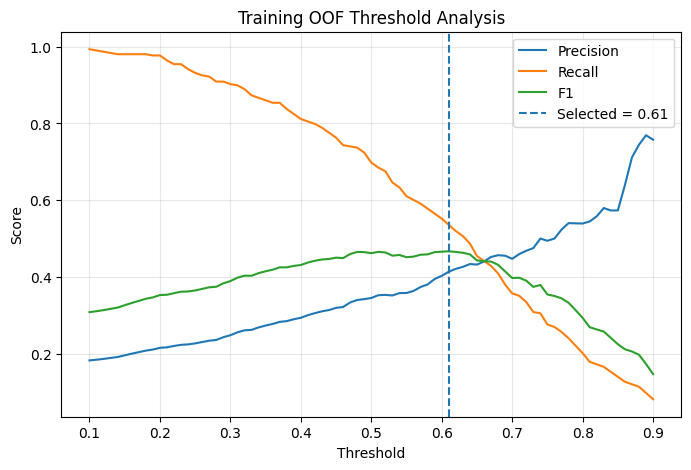

In [ ]:
# ------------------ Stage 12: Training-Only Threshold Selection ------------------

# Select the model with the best training CV ROC-AUC.
selected_model_name = max(
    searches, key=lambda name: searches[name].best_score_
)
selected_pipeline = optimized_pipelines[selected_model_name]

oof_probabilities = cross_val_predict(
    selected_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_rows = []
threshold_grid = np.arange(0.10, 0.91, 0.01)

for threshold in threshold_grid:
    pred = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_df.loc[threshold_df["F1"].idxmax(), "Threshold"]
)

print("Selected model:", selected_model_name)
print("Training OOF threshold maximizing F1:", round(best_threshold, 2))
display(threshold_df.loc[threshold_df["F1"].idxmax()].to_frame("Selected threshold result"))

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Training OOF Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Stage 13: Final test evaluation

The selected tuned pipeline and threshold are now evaluated on the hold-out test set. Do not change the threshold after seeing these results. Report both the default 0.50 threshold and the training-selected threshold.

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
Default threshold 0.50,0.7223,0.3580,0.7532,0.4854,0.803,0.195
Training-selected threshold 0.61,0.7833,0.4159,0.6104,0.4947,0.803,0.195



Classification report at selected threshold:
                         precision    recall  f1-score   support

No baseline obstruction       0.91      0.82      0.86       366
   Baseline obstruction       0.42      0.61      0.49        77

               accuracy                           0.78       443
              macro avg       0.66      0.72      0.68       443
           weighted avg       0.82      0.78      0.80       443



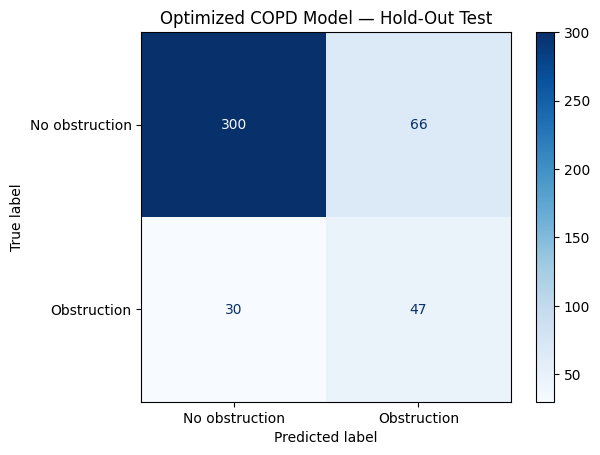

Confusion matrix:
[[300  66]
 [ 30  47]]


In [ ]:
# ------------------ Stage 13: Final Hold-Out Test Evaluation ------------------

final_probabilities = selected_pipeline.predict_proba(X_test)[:, 1]

default_metrics = calculate_metrics(
    y_test, final_probabilities, threshold=0.50
)
selected_metrics = calculate_metrics(
    y_test, final_probabilities, threshold=best_threshold
)

final_metrics_df = pd.DataFrame(
    [default_metrics, selected_metrics],
    index=["Default threshold 0.50", f"Training-selected threshold {best_threshold:.2f}"]
)

display(final_metrics_df.round(4))

final_predictions = (final_probabilities >= best_threshold).astype(int)

print("\nClassification report at selected threshold:")
print(classification_report(
    y_test, final_predictions,
    target_names=["No baseline obstruction", "Baseline obstruction"],
    zero_division=0
))

cm = confusion_matrix(y_test, final_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No obstruction", "Obstruction"]
).plot(cmap="Blues")
plt.title("Optimized COPD Model — Hold-Out Test")
plt.show()

print("Confusion matrix:")
print(cm)

In [ ]:
# ------------------ Export: COPD Final Metrics ------------------

final_metrics_df.to_csv("copd_final_metrics.csv", index=False)

from google.colab import files
files.download("copd_final_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Additional Experiment 1: Random Forest Performance Investigation

### Objective
Investigate why Random Forest accuracy and precision decreased after hyperparameter optimization.

### Approach
- Generate training-only out-of-fold predictions using the optimized Random Forest pipeline.
- Evaluate multiple classification thresholds.
- Compare accuracy, precision, recall, and F1-score.
- Identify thresholds that may improve accuracy and precision.
- Evaluate selected thresholds on the untouched test set.

### Important
- Preserve the original baseline and optimized model results.
- Do not use test data for threshold selection.
- Treat this as an additional experiment, not proof that Random Forest is the best model.

Optimized model: Random Forest

Best training OOF accuracy threshold:


,Result
Threshold,0.770000
Accuracy,0.836723
Precision,0.655738
Recall,0.129870
F1,0.216802



Best training OOF F1 threshold:


,Result
Threshold,0.470000
Accuracy,0.682486
Precision,0.319602
Recall,0.730519
F1,0.444664


,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.2073,0.1781,0.9838,0.3016
1,0.11,0.2266,0.1818,0.9838,0.3068
2,0.12,0.2463,0.1857,0.9838,0.3124
3,0.13,0.2701,0.1906,0.9838,0.3193
4,0.14,0.2944,0.1959,0.9838,0.3267
...,...,...,...,...,...
76,0.86,0.8277,0.8000,0.0130,0.0256
77,0.87,0.8271,0.7500,0.0097,0.0192
78,0.88,0.8260,0.5000,0.0032,0.0065
79,0.89,0.8260,0.5000,0.0032,0.0065


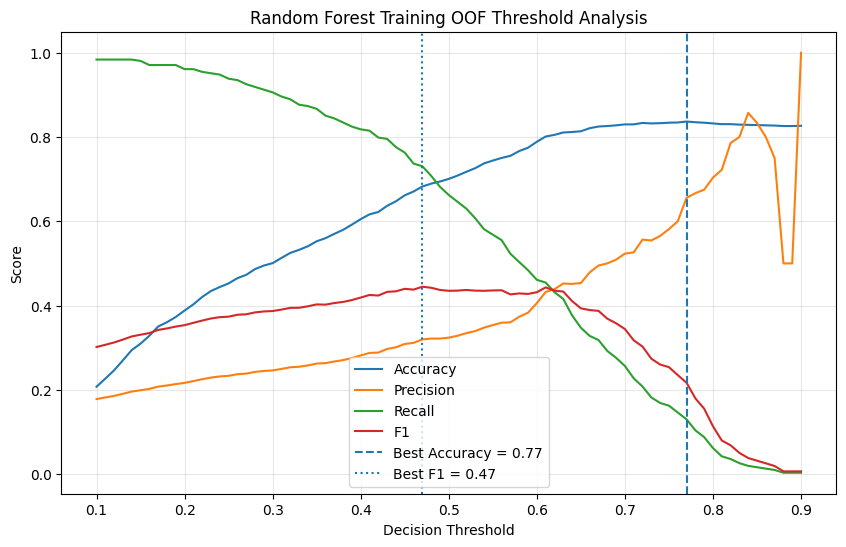

In [ ]:
# ------------------ Additional Experiment 1: Random Forest Threshold Investigation ------------------

# Select the existing optimized Random Forest pipeline.
rf_pipeline = optimized_pipelines["Random Forest"]

# Generate training-only out-of-fold probabilities.
rf_oof_probabilities = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate candidate thresholds.
rf_threshold_grid = np.arange(0.10, 0.91, 0.01)
rf_threshold_rows = []

for threshold in rf_threshold_grid:
    predictions = (rf_oof_probabilities >= threshold).astype(int)

    rf_threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_rows)

# Identify accuracy-oriented and F1-oriented thresholds.
rf_best_accuracy = rf_threshold_df.loc[
    rf_threshold_df["Accuracy"].idxmax()
]

rf_best_f1 = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

print("Optimized model: Random Forest")

print("\nBest training OOF accuracy threshold:")
display(rf_best_accuracy.to_frame("Result"))

print("\nBest training OOF F1 threshold:")
display(rf_best_f1.to_frame("Result"))

# Display the complete threshold comparison.
display(rf_threshold_df.round(4))

# Plot threshold performance.
plt.figure(figsize=(10, 6))

for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    plt.plot(
        rf_threshold_df["Threshold"],
        rf_threshold_df[metric],
        label=metric
    )

plt.axvline(
    rf_best_accuracy["Threshold"],
    linestyle="--",
    label=f"Best Accuracy = {rf_best_accuracy['Threshold']:.2f}"
)

plt.axvline(
    rf_best_f1["Threshold"],
    linestyle=":",
    label=f"Best F1 = {rf_best_f1['Threshold']:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Random Forest Training OOF Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:

# ------------------ Additional Experiment 1: Random Forest Test Evaluation ------------------

rf_test_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

rf_test_thresholds = {
    "Default (0.50)": 0.50,
    "Accuracy-selected": float(rf_best_accuracy["Threshold"]),
    "F1-selected": float(rf_best_f1["Threshold"])
}

rf_test_rows = []

for name, threshold in rf_test_thresholds.items():

    predictions = (rf_test_probabilities >= threshold).astype(int)

    rf_test_rows.append({
        "Threshold Type": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, rf_test_probabilities),
        "Brier Score": brier_score_loss(
            y_test, rf_test_probabilities
        )
    })

rf_test_results_df = pd.DataFrame(rf_test_rows)

print("Random Forest Hold-Out Test Comparison:")
display(rf_test_results_df.round(4))

for name, threshold in rf_test_thresholds.items():

    predictions = (rf_test_probabilities >= threshold).astype(int)

    print(f"\n{name} | Threshold = {threshold:.2f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

Random Forest Hold-Out Test Comparison:


,Threshold Type,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Brier Score
0,Default (0.50),0.50,0.6930,0.3275,0.7273,0.4516,0.789,0.1864
1,Accuracy-selected,0.77,0.8352,0.6000,0.1558,0.2474,0.789,0.1864
2,F1-selected,0.47,0.6659,0.3122,0.7662,0.4436,0.789,0.1864



Default (0.50) | Threshold = 0.50
Confusion Matrix:
[[251 115]
 [ 21  56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.69      0.79       366
           1       0.33      0.73      0.45        77

    accuracy                           0.69       443
   macro avg       0.63      0.71      0.62       443
weighted avg       0.82      0.69      0.73       443


Accuracy-selected | Threshold = 0.77
Confusion Matrix:
[[358   8]
 [ 65  12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       366
           1       0.60      0.16      0.25        77

    accuracy                           0.84       443
   macro avg       0.72      0.57      0.58       443
weighted avg       0.80      0.84      0.79       443


F1-selected | Threshold = 0.47
Confusion Matrix:
[[236 130]
 [ 18  59]]

Classification Report:
              precision    recall  f1-score   

## Additional Experiment 2: Random Forest Hyperparameter Optimization

### Objective
Investigate whether alternative Random Forest hyperparameters can improve the balance between precision, recall, and F1-score.

The original Random Forest optimization prioritized ROC-AUC. This experiment will investigate alternative optimization objectives while preserving the original model and its results.

The experiment will use training data for model selection and reserve the test set for final evaluation.

In [ ]:
# ------------------ Additional Experiment 2: Random Forest Pipeline Inspection ------------------

rf_pipeline = optimized_pipelines["Random Forest"]

print("Random Forest Pipeline:")
print(rf_pipeline)

print("\nAvailable Hyperparameters:")
for param in rf_pipeline.get_params().keys():
    if "__" in param:
        print(param)

Random Forest Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RIDAGEYR',
                                                   'age_started_smoking']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder

### Hyperparameter Search Strategy

Randomized Search CV is used to explore alternative Random Forest configurations.

Three evaluation objectives are considered:
- F1-score: balances precision and recall.
- Recall: prioritizes identifying positive cases.
- ROC-AUC: evaluates the model's ability to distinguish between classes.

All hyperparameter selection is performed using training data and stratified 5-fold cross-validation. The hold-out test set remains untouched during optimization.

In [ ]:
# ------------------ Additional Experiment 2: Random Forest Hyperparameter Optimization ------------------

from sklearn.model_selection import RandomizedSearchCV

rf_param_distributions = {
    "classifier__n_estimators": [300, 400, 500, 700],
    "classifier__max_depth": [None, 3, 4, 5, 6, 8, 10],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [2, 4, 6, 8, 10, 12],
    "classifier__max_features": ["sqrt", "log2", 0.5, 0.7, 0.9],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample",
        None
    ]
}

rf_search = RandomizedSearchCV(
    estimator=optimized_pipelines["Random Forest"],
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

rf_search.fit(X_train, y_train)

print("Random Forest Hyperparameter Search Completed")

print("\nBest F1 CV Score:")
print(round(rf_search.best_score_, 4))

print("\nBest Parameters (F1 Objective):")
print(rf_search.best_params_)

rf_cv_results = pd.DataFrame(rf_search.cv_results_)

best_f1_index = rf_cv_results["rank_test_f1"].idxmin()
best_recall_index = rf_cv_results["rank_test_recall"].idxmin()
best_auc_index = rf_cv_results["rank_test_roc_auc"].idxmin()

rf_objective_comparison = pd.DataFrame([
    {
        "Objective": "F1",
        "Mean CV F1": rf_cv_results.loc[best_f1_index, "mean_test_f1"],
        "Mean CV Recall": rf_cv_results.loc[best_f1_index, "mean_test_recall"],
        "Mean CV ROC-AUC": rf_cv_results.loc[best_f1_index, "mean_test_roc_auc"]
    },
    {
        "Objective": "Recall",
        "Mean CV F1": rf_cv_results.loc[best_recall_index, "mean_test_f1"],
        "Mean CV Recall": rf_cv_results.loc[best_recall_index, "mean_test_recall"],
        "Mean CV ROC-AUC": rf_cv_results.loc[best_recall_index, "mean_test_roc_auc"]
    },
    {
        "Objective": "ROC-AUC",
        "Mean CV F1": rf_cv_results.loc[best_auc_index, "mean_test_f1"],
        "Mean CV Recall": rf_cv_results.loc[best_auc_index, "mean_test_recall"],
        "Mean CV ROC-AUC": rf_cv_results.loc[best_auc_index, "mean_test_roc_auc"]
    }
])

print("\nComparison of Best Configurations by CV Objective:")
display(rf_objective_comparison.round(4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Random Forest Hyperparameter Search Completed

Best F1 CV Score:
0.4448

Best Parameters (F1 Objective):
{'classifier__n_estimators': 700, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.9, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced_subsample'}

Comparison of Best Configurations by CV Objective:


,Objective,Mean CV F1,Mean CV Recall,Mean CV ROC-AUC
0,F1,0.4448,0.6264,0.7596
1,Recall,0.4337,0.6916,0.7638
2,ROC-AUC,0.4375,0.6365,0.7662


### Hold-Out Test Evaluation

The best Random Forest configurations selected using F1-score, Recall, and ROC-AUC are evaluated on the same hold-out test set.

This comparison examines whether differences observed during cross-validation generalize to unseen data.

In [ ]:
# ------------------ Additional Experiment 2: Hold-Out Test Evaluation ------------------

from sklearn.base import clone

rf_objective_models = {
    "F1 Optimized": rf_search.best_estimator_,
    "Recall Optimized": clone(optimized_pipelines["Random Forest"]).set_params(
        **rf_cv_results.loc[best_recall_index, "params"]
    ),
    "ROC-AUC Optimized": clone(optimized_pipelines["Random Forest"]).set_params(
        **rf_cv_results.loc[best_auc_index, "params"]
    )
}

rf_objective_test_rows = []

for model_name, model in rf_objective_models.items():
    if model_name != "F1 Optimized":
        model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    rf_objective_test_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities)
    })

rf_objective_test_df = pd.DataFrame(rf_objective_test_rows)

print("Random Forest: Hold-Out Test Comparison")
display(rf_objective_test_df.round(4))

Random Forest: Hold-Out Test Comparison


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Brier Score
0,F1 Optimized,0.7201,0.3503,0.7143,0.4701,0.7831,0.1785
1,Recall Optimized,0.6749,0.3169,0.7532,0.4462,0.7881,0.1931
2,ROC-AUC Optimized,0.7201,0.3503,0.7143,0.4701,0.7903,0.1805


### Final Comparison: Random Forest Experiments

This comparison summarizes the baseline model, original ROC-AUC optimized model, and additional configurations optimized using F1-score and Recall.

The objective is to understand how different optimization strategies affect classification performance on the same hold-out test set.

In [ ]:
# ------------------ Additional Experiment 2: Final Random Forest Comparison ------------------

rf_final_comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "Accuracy": 0.8014,
        "Precision": 0.3962,
        "Recall": 0.2727,
        "F1": 0.3231,
        "ROC-AUC": 0.7309
    },
    {
        "Model": "Original Optimized RF",
        "Accuracy": 0.6930,
        "Precision": 0.3275,
        "Recall": 0.7273,
        "F1": 0.4516,
        "ROC-AUC": 0.7890
    },
    *[
        {
            "Model": row["Model"],
            "Accuracy": row["Accuracy"],
            "Precision": row["Precision"],
            "Recall": row["Recall"],
            "F1": row["F1"],
            "ROC-AUC": row["ROC-AUC"]
        }
        for _, row in rf_objective_test_df.iterrows()
    ]
])

display(rf_final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline Random Forest,0.8014,0.3962,0.2727,0.3231,0.7309
1,Original Optimized RF,0.6930,0.3275,0.7273,0.4516,0.7890
2,F1 Optimized,0.7201,0.3503,0.7143,0.4701,0.7831
3,Recall Optimized,0.6749,0.3169,0.7532,0.4462,0.7881
4,ROC-AUC Optimized,0.7201,0.3503,0.7143,0.4701,0.7903


## Stage 14: ROC and precision-recall analysis

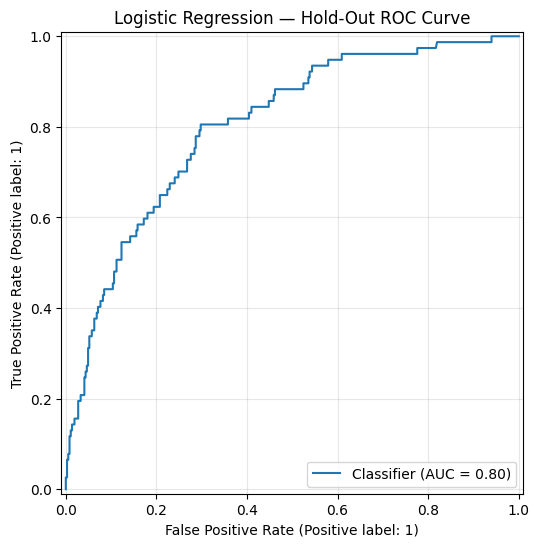

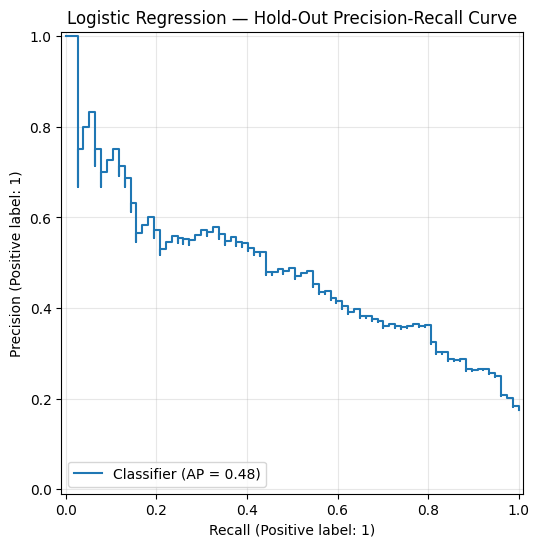

Average precision: 0.4821


In [ ]:
# ------------------ Stage 14: Discrimination Curves ------------------

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, average_precision_score

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, final_probabilities, ax=ax)
ax.set_title(f"{selected_model_name} — Hold-Out ROC Curve")
ax.grid(alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(y_test, final_probabilities, ax=ax)
ax.set_title(f"{selected_model_name} — Hold-Out Precision-Recall Curve")
ax.grid(alpha=0.3)
plt.show()

print("Average precision:", round(
    average_precision_score(y_test, final_probabilities), 4
))

## Stage 15: Probability calibration

Calibration checks whether predicted probabilities correspond to observed event frequencies. A model can rank participants reasonably well but still produce poorly calibrated probabilities. Calibration is fitted using training data only; the test set is used only for assessment.

,Model,Brier Score,ROC-AUC
0,Uncalibrated,0.1950,0.8030
1,Sigmoid calibrated,0.1163,0.8029


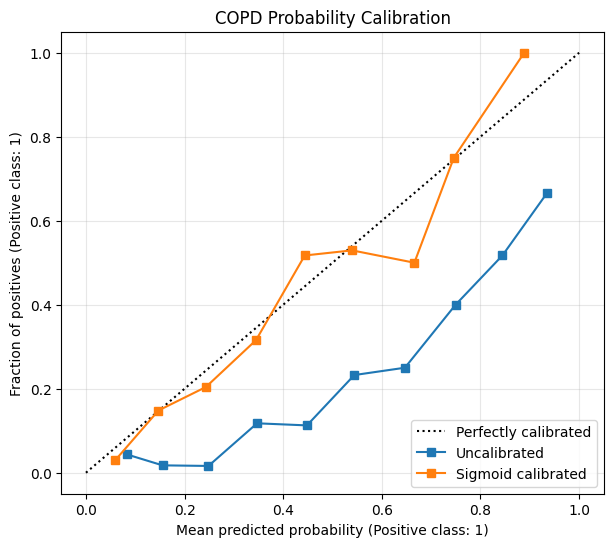

In [ ]:
# ------------------ Stage 15: Calibration Assessment ------------------

# Calibrate the selected model using cross-validation on training data.
calibrated_model = CalibratedClassifierCV(
    estimator=selected_pipeline,
    method="sigmoid",
    cv=cv
)
calibrated_model.fit(X_train, y_train)

calibrated_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

calibration_results = pd.DataFrame({
    "Model": ["Uncalibrated", "Sigmoid calibrated"],
    "Brier Score": [
        brier_score_loss(y_test, final_probabilities),
        brier_score_loss(y_test, calibrated_probabilities)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, final_probabilities),
        roc_auc_score(y_test, calibrated_probabilities)
    ]
})
display(calibration_results.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_test, final_probabilities, n_bins=10,
    name="Uncalibrated", ax=ax
)
CalibrationDisplay.from_predictions(
    y_test, calibrated_probabilities, n_bins=10,
    name="Sigmoid calibrated", ax=ax
)
ax.set_title("COPD Probability Calibration")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
# ------------------ Export: COPD Calibration Results ------------------

calibration_results.to_csv("copd_calibration_results.csv", index=False)

from google.colab import files
files.download("copd_calibration_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 16: Save final artifacts

The saved artifact is a complete scikit-learn pipeline, including preprocessing and the calibrated classifier. This makes inference simpler and reduces the risk of applying different preprocessing at deployment.

In [ ]:
# ------------------ Stage 16: Save Optimized Model ------------------

# Save both calibrated and uncalibrated pipelines for reproducibility.
joblib.dump(
    calibrated_model,
    "copd_optimized_calibrated_pipeline.pkl"
)
joblib.dump(
    selected_pipeline,
    "copd_optimized_pipeline.pkl"
)

metadata = {
    "target": "baseline_obstruction_flag",
    "target_definition": "Baseline pre-bronchodilator FEV1/FVC < 0.70",
    "selected_model": selected_model_name,
    "training_selected_threshold": best_threshold,
    "features": list(X_train.columns),
    "random_state": RANDOM_STATE
}
joblib.dump(metadata, "copd_optimized_metadata.pkl")

print("Saved:")
print("- copd_optimized_calibrated_pipeline.pkl")
print("- copd_optimized_pipeline.pkl")
print("- copd_optimized_metadata.pkl")

Saved:
- copd_optimized_calibrated_pipeline.pkl
- copd_optimized_pipeline.pkl
- copd_optimized_metadata.pkl



# Stage 17: Final Summary and Key Findings

## 1. Model Performance Comparison

### Baseline vs Optimized Models

| Model | Version | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---:|---:|---:|---:|---:|
| Logistic Regression | Baseline | 0.7178 | 0.3537 | 0.7532 | 0.4813 | 0.8021 |
| Logistic Regression | Optimized | 0.7223 | 0.3580 | 0.7532 | 0.4854 | 0.8030 |
| Random Forest | Baseline | 0.8014 | 0.3962 | 0.2727 | 0.3231 | 0.7309 |
| Random Forest | Optimized | 0.6930 | 0.3275 | 0.7273 | 0.4516 | 0.7890 |
| XGBoost | Baseline | 0.8284 | 0.5152 | 0.2208 | 0.3091 | 0.7657 |
| XGBoost | Optimized | 0.8375 | 0.5490 | 0.3636 | 0.4375 | 0.7969 |

**Key Findings:**
- Best cross-validation ROC-AUC: Logistic Regression (0.7772).
- Random Forest showed the largest recall improvement: 0.2727 → 0.7273.
- XGBoost achieved the highest optimized accuracy (0.8375) and precision (0.5490).
- Logistic Regression achieved the highest optimized F1-score (0.4854) and test ROC-AUC (0.8030).
- Logistic Regression was selected based on its highest cross-validation ROC-AUC.

## 2. Selected Model and Classification Threshold

- **Selected Model:** Optimized Logistic Regression.
- **Selected Threshold:** 0.61.
- **Selection Method:** Highest cross-validation ROC-AUC for model selection and maximum F1-score using training out-of-fold predictions for threshold selection.
- The threshold was selected without directly optimizing on the test set.

## 3. Final Test-Set Evaluation

**Test Set:** 443 participants (366 negative, 77 positive).

| Metric | Threshold 0.50 | Threshold 0.61 |
|---|---:|---:|
| Accuracy | 0.7223 | 0.7833 |
| Precision | 0.3580 | 0.4159 |
| Recall | 0.7532 | 0.6104 |
| F1-score | 0.4854 | 0.4947 |
| ROC-AUC | 0.8030 | 0.8030 |
| Brier Score | 0.1950 | 0.1950 |

**Confusion Matrix (Threshold = 0.61):**

| | Predicted Negative | Predicted Positive |
|---|---:|---:|
| Actual Negative | 300 | 66 |
| Actual Positive | 30 | 47 |

**Key Findings:**
- Accuracy improved by 6.10 percentage points.
- Precision improved by 5.79 percentage points.
- Recall decreased by 14.28 percentage points.
- F1-score improved by 0.0093.
- ROC-AUC remained unchanged.

## 4. Feature Ablation Analysis

The contribution of emphysema (`MCQ160G`) and chronic bronchitis (`MCQ160K`) history features was evaluated.

| Feature Set | Features | CV ROC-AUC | Accuracy | Precision | Recall | F1-score | Test ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|---:|
| All selected features | 14 | 0.7772 | 0.7223 | 0.3580 | 0.7532 | 0.4854 | 0.8030 |
| Without disease-history features | 12 | 0.7769 | 0.7291 | 0.3681 | 0.7792 | 0.5000 | 0.8040 |

**Key Findings:**
- Removing both disease-history features slightly improved hold-out accuracy, precision, recall, F1-score, and ROC-AUC.
- Cross-validation ROC-AUC remained almost unchanged (0.7772 vs 0.7769).
- The model retained useful predictive ability without these features.
- The differences are small and based on one test split; they do not establish better generalization.
- The final threshold evaluation uses the 14-feature model; the 12-feature result is an exploratory ablation.

## 5. Model Calibration

| Model | Brier Score | ROC-AUC |
|---|---:|---:|
| Uncalibrated | 0.1950 | 0.8030 |
| Sigmoid Calibrated | 0.1163 | 0.8029 |

**Key Findings:**
- Brier score decreased from 0.1950 to 0.1163.
- Relative Brier score reduction: approximately 40.36%.
- ROC-AUC remained nearly unchanged.
- Sigmoid calibration improved probability quality on the evaluated test set.
- Independent validation is required to confirm calibration performance.

## 6. Additional Random Forest Investigation

To investigate the reduction in accuracy and precision observed after the original Random Forest optimization, additional experiments were conducted to examine decision-threshold selection and alternative hyperparameter optimization objectives.

### 6.1 Threshold Investigation

Different classification thresholds were evaluated using training out-of-fold predictions and subsequently assessed on the hold-out test set.

| Threshold Strategy | Threshold | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|---:|
| Default | 0.50 | 0.6930 | 0.3275 | 0.7273 | 0.4516 |
| Accuracy-selected | 0.77 | 0.8352 | 0.6000 | 0.1558 | 0.2474 |
| F1-selected | 0.47 | 0.6859 | 0.3122 | 0.7662 | 0.4436 |

**Key Findings:**
- Increasing the threshold improved accuracy and precision but substantially reduced recall.
- The default threshold achieved the highest test F1-score among the three evaluated thresholds.
- Threshold adjustment demonstrated the trade-off between identifying positive cases and reducing false positives.

### 6.2 Alternative Hyperparameter Optimization

Random Forest hyperparameters were additionally optimized using three cross-validation objectives: F1-score, recall, and ROC-AUC.

**Cross-validation comparison:**

| Optimization Objective | Mean CV F1 | Mean CV Recall | Mean CV ROC-AUC |
|---|---:|---:|---:|
| F1 | 0.4448 | 0.6264 | 0.7596 |
| Recall | 0.4337 | 0.6916 | 0.7638 |
| ROC-AUC | 0.4375 | 0.6365 | 0.7662 |

**Hold-out test comparison:**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Original Optimized RF | 0.6930 | 0.3275 | 0.7273 | 0.4516 | 0.7890 |
| F1 Optimized RF | 0.7201 | 0.3503 | 0.7143 | 0.4701 | 0.7831 |
| Recall Optimized RF | 0.6749 | 0.3169 | 0.7532 | 0.4462 | 0.7881 |
| ROC-AUC Optimized RF | 0.7201 | 0.3503 | 0.7143 | 0.4701 | 0.7903 |

**Key Findings:**
- F1-based optimization achieved the highest test F1-score of 0.4701.
- Recall-based optimization achieved the highest test recall of 0.7532.
- ROC-AUC-based optimization achieved the highest test ROC-AUC of 0.7903.
- The alternative configurations demonstrated different precision-recall trade-offs.
- Improvements were modest and do not establish definitive superiority over the original configuration.

## 7. Limitations

- Target represents pre-bronchodilator spirometric airflow obstruction (FEV1/FVC < 0.70), not clinically confirmed COPD.
- Dataset is restricted to NHANES 2011–2012.
- Class imbalance may affect positive-class prediction performance.
- Self-reported emphysema and chronic bronchitis history may act as proxy features.
- Model and feature comparisons rely on a single hold-out split.
- Hyperparameter selection followed by OOF threshold selection may introduce selection bias.
- Generalization to other populations has not been established.
- Independent external validation is required before clinical application.

## 8. Conclusion

- Optimized Logistic Regression achieved a test ROC-AUC of **0.8030** and was selected based on the highest cross-validation ROC-AUC.
- The training-selected threshold of 0.61 improved test accuracy and F1-score but reduced recall.
- Feature ablation showed that useful predictive performance was retained without emphysema and chronic bronchitis history features.
- Sigmoid calibration reduced the Brier score from 0.1950 to 0.1163, representing an approximately 40.36% reduction.
- Additional Random Forest experiments demonstrated that different optimization objectives and classification thresholds produce different accuracy, precision, and recall trade-offs.
- The results provide a research foundation for COPD risk modelling, but do not establish clinical diagnostic capability or general population performance.
